# From shop tables to model context with Kumo Engine

**Business question:** a storage vendor's account team wants a ranked list of the accounts most likely to place an order in the next 30 days, so it can plan outreach and forecast the month.
The data is three tables, customers, products and orders, like an export from a CRM or an order system.

Kumo Engine is NVIDIA's open-source accelerator for **context generation** over relational data.
It stores the tables and their relationships as a graph on disk.
For each customer and point in time, it samples that customer's related records up to that time; this is the model's *context*.
A graph neural network (GNN) learns from those contexts directly, without hand-built features.
This notebook makes each of those steps visible:

| Step | What Kumo Engine does | Business meaning |
| --- | --- | --- |
| 1–3. Tables and graph | Declares keys, types and the links between tables | Describe the data once, as it already exists |
| 4. Snapshot | Builds DiskGraph, the on-disk graph index (Rust) that context is sampled from | The same index scales past memory on an NVMe disk |
| 5. Context generation | Samples each customer's newest orders and their products, only up to the anchor time | The model sees what an account manager could have known at that moment, never the future |
| 6. Predictive query | Turns order history into labelled examples, one per customer per anchor time, each with its own context | One line of PQL replaces hand-written labels and point-in-time joins |
| 7. Training | Trains a GNN on those contexts (FAST preset, CPU) | No feature engineering |
| 8. Batch predictions | Generates each customer's context as of 15 November and scores it; shows the context Kumo generated | A ranked call list for the next 30 days |

The data is synthetic and the notebook runs locally on a Mac CPU in under a minute.
It was run with Kumo Engine `1.0.0.dev0+5d17fb3`, a wheel built from the `main` branch of [NVIDIA/kumo-engine](https://github.com/NVIDIA/kumo-engine): PyPI's `1.0.1` has no macOS wheel.
Three calls used here exist only in `main`, not in `1.0.1`: `Graph.visualize()`, `Trainer.predict(entities=...)` and prediction explanations with sampled subgraphs.
The README has the setup steps.

Every output is Kumo's own unless the cell says it is a pandas illustration or annotation.

Docs: [Graphs](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs) · [Predictive queries](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/predictive-queries) · [Training tables](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training-tables) · [Training](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training) · [Making predictions](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/making-predictions)

## Set up the notebook

Run this in the `.venv` kernel from the README.
The cell imports Kumo and prints the versions, including whether torch can see the Apple GPU (MPS); this run stays on the CPU either way.

In [1]:
import contextlib
import io
import logging
import shutil
import time
import warnings
from pathlib import Path

# Known, harmless messages on this stack (Python 3.14, pandas 2.3 with NumPy 2.5, CPU-only Lightning).
for message in [r".*torch\.jit\.script", r"IProgress not found", r"The 'generic' unit for NumPy timedelta",
                r".*does not have many workers", r"GPU available but not used",
                r"Converting a tensor with requires_grad=True", r"Be aware that when using `ckpt_path`",
                r"The dirpath has changed"]:
    warnings.filterwarnings("ignore", message=message)

import numpy as np
import pandas as pd
import pytorch_lightning
import torch
import kumo.engine as kumo
from kumoapi.model_plan import RunMode
from kumoapi.typing import Dtype, Stype

pd.set_option("display.max_colwidth", None)
logging.getLogger("optuna").setLevel(logging.WARNING)


class HideCheckpointPaths(logging.Filter):
    """Drop Lightning's 'Restoring states / Loaded model weights from <long path>' lines."""
    def filter(self, record):
        return not record.getMessage().startswith(("Restoring states", "Loaded model weights"))


for handler in logging.getLogger("pytorch_lightning").handlers:
    handler.addFilter(HideCheckpointPaths())


@contextlib.contextmanager
def quiet_lightning():
    """Hide Lightning's progress bars and INFO lines during a prediction call."""
    lightning_logger = logging.getLogger("pytorch_lightning")
    level = lightning_logger.level
    lightning_logger.setLevel(logging.WARNING)
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            yield
    finally:
        lightning_logger.setLevel(level)


print("kumo-engine:", kumo.__version__)
print("torch:", torch.__version__, "| Apple GPU (MPS) visible to torch:", torch.backends.mps.is_available())

kumo-engine: 1.0.0.dev0+5d17fb3
torch: 2.15.0 | Apple GPU (MPS) visible to torch: True


### Parameters

All values you might change are here.
Everything the notebook writes goes under `./scratch`, and the cleanup cell at the end removes exactly the paths in `CREATED`.
`kumo.configure` points Kumo's working data (snapshots, training tables, models) at `./scratch/kumo_work` instead of `~/.cache/kumo-engine`.

In [2]:
SCRATCH = Path("scratch")
DATA_DIR = SCRATCH / "shop_csv"             # the three source tables
SCORING_DIR = SCRATCH / "scoring"           # rows to score in section 8
KUMO_WORK = SCRATCH / "kumo_work"           # Kumo's snapshots, training tables and models
PREDICTIONS_CSV = SCRATCH / "predictions.csv"

PREDICTION_TIME = pd.Timestamp("2026-11-15")  # last day of order history
CUT_OFF = pd.Timestamp("2026-10-15")          # the "as of" date in section 5
FAN_OUT = 10                                  # neighbours per hop (sections 5 and 7)
ACCELERATOR = "cpu"
CLEAN_UP = True                               # False keeps ./scratch outputs for inspection
RANDOM_SEED = 7

CREATED = [DATA_DIR, SCORING_DIR, KUMO_WORK, PREDICTIONS_CSV]
SCRATCH.mkdir(exist_ok=True)
kumo.configure(scratch_dir=KUMO_WORK.resolve())

## Generate synthetic example data

Run the next cell to write three CSV files to `scratch/shop_csv/`: 500 customers, 10 products and 1,063 orders from January 2025 to 15 November 2026.
You can skim the generation code; the Kumo workflow starts in section 1.

A few fixed rows each demonstrate one rule later on:

| Fixed rows | Demonstrates |
| --- | --- |
| Acme (C001): exactly 3 orders, 988, 1017 and 1043 | the sampled neighbourhood, the training labels and the "as of" cut-off |
| Globex (C002): 25 orders | the cap on neighbours per hop |
| Initech (C003): no orders | an empty neighbourhood |
| One order for C999, a customer that doesn't exist | an unmatched link |

Order IDs follow order dates, which is why Acme's orders are numbered 988, 1017 and 1043.
Everyone else orders at random, with heavy-tailed activity and some customers who stop buying, so the model has a recency and frequency pattern to learn.

In [3]:
rng = np.random.default_rng(RANDOM_SEED)

# Customers: four named accounts plus 496 generated ones. Every signup predates the first order.
named = [("C001", "Acme", "West"), ("C002", "Globex", "East"),
         ("C003", "Initech", "West"), ("C004", "Umbrella", "East")]
first = ["Blue", "North", "Silver", "Red", "Iron", "Bright", "Granite", "Cedar", "Harbor", "Summit",
         "Maple", "Pioneer", "Crescent", "Falcon", "Orchid", "Lakeside", "Copper", "Evergreen", "Atlas", "Juniper"]
second = ["Analytics", "Logistics", "Health", "Foods", "Systems", "Media", "Labs", "Energy", "Finance",
          "Robotics", "Retail", "Networks", "Studios", "Motors", "Pharma", "Holdings", "Telecom", "Insurance",
          "Freight", "Biotech", "Capital", "Software", "Textiles", "Aerospace", "Clinics"]
generated = rng.choice([f"{a} {b}" for a in first for b in second], size=496, replace=False)
customers_df = pd.DataFrame({
    "customer_id": [f"C{i:03d}" for i in range(1, 501)],
    "name": [n for _, n, _ in named] + list(generated),
    "region": [r for _, _, r in named] + list(rng.choice(["West", "East", "Central", "South"], 496)),
    "signup_date": pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 1096, 500), unit="D"),
})

products_df = pd.DataFrame({
    "product_id": [f"P{i}" for i in range(1, 11)],
    "name": ["FlashArray//X", "Support renewal", "FlashArray//C", "Evergreen//One", "Portworx",
             "Pure1", "Cloud Block Store", "Professional services", "FlashBlade//S", "FlashBlade//E"],
    "category": ["Hardware", "Services", "Hardware", "Subscription", "Software",
                 "Software", "Software", "Services", "Hardware", "Hardware"],
    "price": [1200, 300, 800, 500, 250, 100, 400, 600, 900, 700],
})

# Orders. Random dates fill the gaps around Acme's fixed orders, so numbering by date
# puts Acme's orders at exactly 988, 1017 and 1043.
acme_orders = [("2026-09-30", "P9", 450), ("2026-10-14", "P2", 300), ("2026-11-02", "P9", 900)]
gaps = [("2025-01-01", "2026-09-29", 987), ("2026-10-01", "2026-10-13", 28),
        ("2026-10-15", "2026-11-01", 25), ("2026-11-03", "2026-11-15", 20)]
dates = []
for start, end, count in gaps:
    days = pd.date_range(start, end, freq="D")
    growth = np.linspace(1.0, 1.5, len(days))  # the shop grows a little over time
    dates.append(np.sort(rng.choice(days, size=count, p=growth / growth.sum())))
dates = pd.DatetimeIndex(np.concatenate(dates))

others = customers_df.customer_id[4:].to_numpy()        # C005..C500
activity = rng.lognormal(0.0, 1.3, len(others))          # a few customers order a lot
churned = rng.random(len(others)) < 0.3
churn_date = pd.Timestamp("2025-03-01") + pd.to_timedelta(rng.integers(0, 600, len(others)), unit="D")
owner = np.array([rng.choice(others, p=(w := activity * (~churned | (churn_date > d))) / w.sum())
                  for d in dates], dtype=object)
owner[rng.choice(len(dates), 25, replace=False)] = "C002"  # Globex
owner[rng.choice(np.flatnonzero(owner != "C002"))] = "C999"  # a customer that doesn't exist
popularity = np.array([10, 14, 8, 9, 7, 6, 5, 4, 8, 6], dtype=float)
product = rng.choice(products_df.product_id, size=len(dates), p=popularity / popularity.sum())
list_price = products_df.set_index("product_id").price.loc[product].to_numpy()

orders_df = pd.concat([
    pd.DataFrame({"customer_id": owner, "product_id": product, "order_date": dates,
                  "amount": (list_price * rng.uniform(0.5, 1.5, len(dates))).round(-1).astype(int)}),
    pd.DataFrame([{"customer_id": "C001", "product_id": p, "order_date": pd.Timestamp(d), "amount": a}
                  for d, p, a in acme_orders]),
]).sort_values("order_date", kind="stable").reset_index(drop=True)
orders_df.insert(0, "order_id", np.arange(1, len(orders_df) + 1))

assert orders_df.loc[orders_df.customer_id == "C001", "order_id"].tolist() == [988, 1017, 1043]
assert (orders_df.customer_id == "C002").sum() == 25 and (orders_df.customer_id == "C003").sum() == 0
assert (~orders_df.customer_id.isin(customers_df.customer_id)).sum() == 1

DATA_DIR.mkdir(parents=True, exist_ok=True)
for table_name, frame in {"customers": customers_df, "products": products_df, "orders": orders_df}.items():
    frame.to_csv(DATA_DIR / f"{table_name}.csv", index=False)
    print(f"{table_name}.csv: {len(frame):,} rows")
orders_df[orders_df.customer_id.isin(["C001", "C999"])]

customers.csv: 500 rows
products.csv: 10 rows
orders.csv: 1,063 rows


,order_id,customer_id,product_id,order_date,amount
816,817,C999,P1,2026-07-02,1680
987,988,C001,P9,2026-09-30,450
1016,1017,C001,P2,2026-10-14,300
1042,1043,C001,P9,2026-11-02,900


## 1. One file = one table

Kumo reads source tables through a connector.
[`FileConnector`](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs) reads CSV and Parquet files below a root folder; each file becomes one source table, named after the file without its suffix.
(It does not read Excel workbooks, so a workbook would first be split into one CSV per sheet.)

Kumo's first look at the files is the raw `dtype` of each column.
The two date columns arrive as `string`, because a CSV has no date type.

In [4]:
files = kumo.FileConnector(root_dir=str(DATA_DIR.resolve()))
print("Tables Kumo can see:", files.table_names())

pd.DataFrame([
    {"table": table_name, "column": column.name, "source dtype": str(column.dtype)}
    for table_name in files.table_names()
    for column in files[table_name].columns
]).pivot_table(index=["table", "column"], values="source dtype", aggfunc="first", sort=False)

Tables Kumo can see: ['customers', 'orders', 'products']


source dtype
table     column                  
customers customer_id       string
          name              string
          region            string
          signup_date       string
orders    order_id           int64
          customer_id       string
          product_id        string
          order_date        string
          amount             int64
products  product_id        string
          name              string
          category          string
          price              int64

## 2. Tables: keys, a time column and inferred types

Declare each table's primary key, `customer_id`, `product_id` and `order_id`, and declare `order_date` as the time column of `orders`.
`infer_metadata()` then picks a physical `dtype` and a semantic `stype` for every column; the stype decides how the model encodes the column (see [Graphs](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs)).

In [5]:
def describe(*tables):
    """One row per column: the dtype and stype Kumo holds, and the column's key or time role."""
    rows = []
    for table in tables:
        definition = table.definition
        for column in definition.cols:
            role = ("primary key" if column.name == definition.pkey
                    else "time column" if column.name == definition.time_col else "")
            rows.append({"table": table.table_name, "column": column.name, "dtype": str(column.dtype),
                         "stype": str(column.stype), "role": role})
    return pd.DataFrame(rows).set_index(["table", "column"])

describe(
    kumo.Table.from_source_table(files["customers"], primary_key="customer_id").infer_metadata(),
    kumo.Table.from_source_table(files["products"], primary_key="product_id").infer_metadata(),
    kumo.Table.from_source_table(files["orders"], primary_key="order_id", time_column="order_date").infer_metadata(),
)

dtype        stype         role
table     column                                       
customers customer_id  string           ID  primary key
          name         string  categorical             
          region       string  categorical             
          signup_date  string  categorical             
products  product_id   string           ID  primary key
          name         string  categorical             
          category     string  categorical             
          price         int64    numerical             
orders    order_id      int64           ID  primary key
          customer_id  string           ID             
          product_id   string           ID             
          order_date   string    timestamp  time column
          amount        int64    numerical

Four corrections before building the graph:

- **`orders.order_date`** is `timestamp` only because it was declared the time column; its dtype is still `string`. Declaring `dtype=Dtype.date` makes Kumo parse it when it stages the data.
- **`customers.signup_date`** came out `categorical`, because inference saw text. Declare it a date and a timestamp. Customers get no time column here, and that is safe because every signup predates the first order.
- **`customers.name`** is `categorical` with one value per customer, 500 distinct names. A model can only memorise it, so leave it out of the customers table. Product names stay: ten values that describe the product.
- **`orders.customer_id` and `orders.product_id`** are foreign keys. Inference judges one table at a time; these are `ID` because their values look like `C001`, but numeric foreign keys would come out `numerical`. Declare `Stype.ID` explicitly.

`with_column` returns a new table, so each correction is chained and the result is kept.

In [6]:
customers = (
    kumo.Table.from_source_table(files["customers"], ["customer_id", "region", "signup_date"],
                                 primary_key="customer_id")
    .infer_metadata()
    .with_column("signup_date", dtype=Dtype.date, stype=Stype.timestamp)
)
products = kumo.Table.from_source_table(files["products"], primary_key="product_id").infer_metadata()
orders = (
    kumo.Table.from_source_table(files["orders"], primary_key="order_id", time_column="order_date")
    .infer_metadata()
    .with_column("order_date", dtype=Dtype.date)
    .with_column("customer_id", stype=Stype.ID)
    .with_column("product_id", stype=Stype.ID)
)
describe(customers, products, orders)

dtype        stype         role
table     column                                       
customers customer_id  string           ID  primary key
          region       string  categorical             
          signup_date    date    timestamp             
products  product_id   string           ID  primary key
          name         string  categorical             
          category     string  categorical             
          price         int64    numerical             
orders    order_id      int64           ID  primary key
          customer_id  string           ID             
          product_id   string           ID             
          order_date     date    timestamp  time column
          amount        int64    numerical

## 3. Build the graph

Each edge goes from a foreign key to the table whose primary key it references.
Kumo stores every edge in both directions, so the model can walk from a customer to its orders and from an order to its product.
`validate()` checks the schemas, keys and key types without reading any rows.

In [7]:
graph = kumo.Graph(
    tables=[customers, products, orders],
    edges=[
        kumo.Edge(src_table="orders", fkey="customer_id", dst_table="customers"),
        kumo.Edge(src_table="orders", fkey="product_id", dst_table="products"),
    ],
)
graph.validate()
print("Graph is valid; graph.id =", graph.id[:16] + "...")

Graph is valid; graph.id = f6e90f0176db671c...


### See the graph

[`graph.visualize()`](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs#visualize-table-relationships) draws the tables, keys (`PK`, `FK`), the time column (`TS`) and the edges from the graph object itself.
It is in this `main` build but not in PyPI's `1.0.1`.

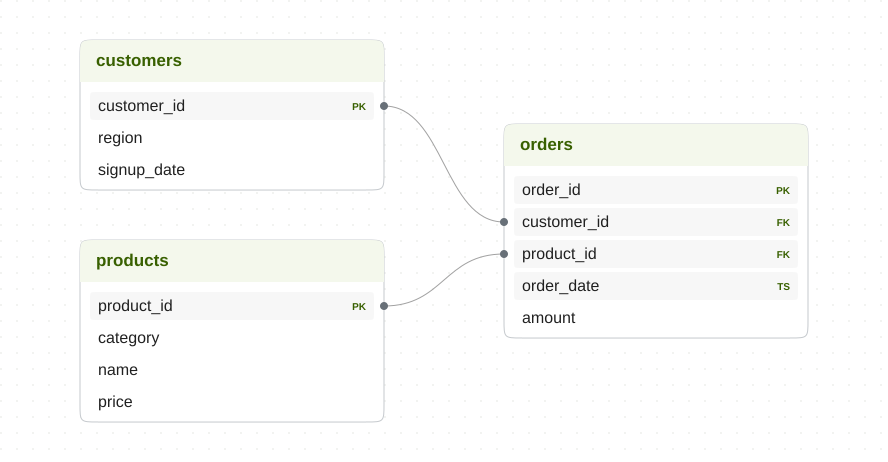

In [8]:
graph.visualize(show_cols=True)

## 4. Snapshot health

`graph.snapshot()` reads every table and builds DiskGraph, Kumo's on-disk graph index, written in Rust.
Every context in sections 5–8 is sampled from this index rather than from the CSV files; on a GPU server it sits on NVMe and feeds the GPU.
The snapshot is the data the model trains on, so check what made it in: rows per table, duplicate keys, and how many orders found their customer.
Kumo raises a `UserWarning` for duplicate or null primary keys, and for a foreign key that matches fewer than half of its rows.

Kumo logs every ingest stage.
The cell collects that log with a logging handler and prints only the per-table row counts and the final summary line.

In [9]:
class CollectLog(logging.Handler):
    """Keep Kumo's ingest log lines instead of printing every stage."""
    def __init__(self):
        super().__init__(logging.INFO)
        self.lines = []

    def emit(self, record):
        self.lines.append(record.getMessage())


ingest_log = CollectLog()
logging.getLogger("kumo_core.diskgraph").addHandler(ingest_log)
logging.getLogger("kumo_core.diskgraph").setLevel(logging.INFO)

started = time.time()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    snapshot = graph.snapshot()
print(f"Snapshot built in {time.time() - started:.1f}s: {snapshot.id[-16:]}")
print("\n".join(line for line in ingest_log.lines
                if "producers complete" in line or "ingest completed" in line))
kumo_warnings = [str(w.message) for w in caught if issubclass(w.category, UserWarning)]
print("Kumo data warnings:", kumo_warnings or "none")

Snapshot built in 2.0s: 308e007eea4179f5
ingest: table producers complete phase="encode" table=customers rows=500 elapsed_ms=7
ingest: table producers complete phase="encode" table=products rows=10 elapsed_ms=1
ingest: table producers complete phase="encode" table=orders rows=1063 elapsed_ms=2
diskgraph ingest completed: 3 node tables, 4 edge relations, 1573 nodes, 4250 edges
Kumo data warnings: none


The last log line already holds the health story.
There are 1,573 nodes, one per row: 500 + 10 + 1,063.
There are 4,250 edges, each link stored in both directions: 2 × (1,062 order → customer links + 1,063 order → product links).
So one order found no customer.

No warning, and none was expected.
C999's order is 1 unmatched row in 1,063, and Kumo warns about a foreign key only below a 50% match rate (`_LOW_FK_MATCH_RATE = 0.5` in `kumo/engine/graph.py`).

For the full table, note that the published API has no `snapshot.stats()`.
Kumo computes a `data/health` table from the snapshot's ingest statistics and sends it to an experiment tracker when `Trainer.fit` finishes, through the public `kumo.engine.tracking.Tracking` protocol.
Section 7 attaches a small tracker and prints that table.

Until then, here is the row Kumo can't link, found with plain pandas on the CSV (not Kumo output):

In [10]:
orders_csv = pd.read_csv(DATA_DIR / "orders.csv", parse_dates=["order_date"])
customer_ids = pd.read_csv(DATA_DIR / "customers.csv").customer_id
orders_csv[~orders_csv.customer_id.isin(customer_ids)]

,order_id,customer_id,product_id,order_date,amount
816,817,C999,P1,2026-07-02,1680


The order stays in the snapshot: it is a valid order, and its product edge still exists.
It gets no edge to a customer, so it can never appear in a customer's neighbourhood or count toward any customer's label.

## 5. Context generation: the neighbourhood Kumo samples

This is the step Kumo Engine accelerates.
The model doesn't read the whole graph for each prediction.
For each customer and anchor time, Kumo samples a small subgraph, the context:

- **Hop 1:** the customer's orders at or before the anchor time, newest first, up to a cap.
- **Hop 2:** the product of each sampled order.

Kumo's fallback is 10 neighbours per hop over 2 hops, newest first (`default_num_neighbors = (10, 10)` and `temporal_strategy = "last"` in `kumo_core/resolved_task.py`).
The FAST plan in section 7 suggests different numbers for this graph, so section 7 sets 10 per hop to keep this rule visible.

The anchor time is what keeps the context honest: a context built "as of" a date contains only records from that date or earlier.
Kumo generates one context per training example (section 6) and one per prediction (section 8).

Before training there is no sampler to call, so the next cell applies the rule with pandas.
**This is an illustration of Kumo's rule, not Kumo output.**
Section 8 asks Kumo's own sampler for the same three contexts and compares.

In [11]:
def illustrate_neighbourhood(customer_id, as_of, fan_out=FAN_OUT):
    """Illustration only (pandas): the newest orders at or before `as_of`, at most `fan_out`."""
    eligible = orders_csv[(orders_csv.customer_id == customer_id) & (orders_csv.order_date <= as_of)]
    hop1 = eligible.sort_values(["order_date", "order_id"], ascending=False).head(fan_out)
    return {"orders available": len(eligible),
            "hop 1: orders sampled": sorted(hop1.order_id.tolist()),
            "hop 2: products": sorted(hop1.product_id.unique().tolist())}

NEIGHBOURHOOD_CASES = {
    "Acme, as of 2026-11-15": ("C001", PREDICTION_TIME),
    "Globex, as of 2026-11-15": ("C002", PREDICTION_TIME),
    "Acme, as of 2026-10-15": ("C001", CUT_OFF),
}
illustration = pd.DataFrame({case: illustrate_neighbourhood(*args)
                             for case, args in NEIGHBOURHOOD_CASES.items()}).T
illustration

,orders available,hop 1: orders sampled,hop 2: products
"Acme, as of 2026-11-15",3,"[988, 1017, 1043]","[P2, P9]"
"Globex, as of 2026-11-15",25,"[689, 693, 811, 815, 864, 869, 873, 897, 934, 1018]","[P1, P10, P2, P5, P7, P8, P9]"
"Acme, as of 2026-10-15",2,"[988, 1017]","[P2, P9]"


- **Acme:** 3 orders lead to 2 distinct products, because orders 988 and 1043 are both FlashBlade//S (P9).
- **Globex:** 25 orders are available, but only the 10 newest fit under the cap.
- **Acme, as of 2026-10-15:** order 1043 (2 November) is in the future, so it isn't there.

## 6. Write the predictive query

The business question in [PQL](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/predictive-queries).
`COUNT(orders.*, 0, 30, days) > 0` is true when a customer has at least one order in the 30 days after the anchor time.
`validate()` checks the query against the graph, and `get_task_type()` reports the kind of prediction problem; expect `binary_classification`.

In [12]:
pquery = kumo.PredictiveQuery(
    graph, "PREDICT COUNT(orders.*, 0, 30, days) > 0 FOR EACH customers.customer_id")
print(pquery.validate())
print("Task type:", pquery.get_task_type())

ValidationResponse(warnings=[], errors=[], info_items=[])
Task type: binary_classification


### Generate the training table

For a temporal query Kumo builds the training examples itself ([Training tables](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training-tables)).
Each row is one customer at one anchor time, and the label is computed from the orders in the 30 days after that anchor.
The anchors step back every 30 days from the last date that still has 30 days of observed future.

In [13]:
training_table = pquery.generate_training_table(snapshot)
train_rows = pd.read_parquet(training_table.train_table_path)
print(f"{len(train_rows):,} rows = {train_rows.ENTITY1.nunique()} customers x "
      f"{train_rows.TIMESTAMP.nunique()} anchor times")
print("Anchors:", train_rows.TIMESTAMP.min().date(), "to", train_rows.TIMESTAMP.max().date(),
      "every", training_table.generation_plan.timeframe_step, "days")
print(f"Positive labels: {train_rows.TARGET1.mean():.1%}")
train_rows.head(3)

10,500 rows = 500 customers x 21 anchor times
Anchors: 2025-02-23 to 2026-10-16 every 30 days
Positive labels: 7.8%


,ENTITY1,TIMESTAMP,TARGET1
0,C126,2025-02-23,False
1,C126,2025-03-25,True
2,C126,2025-04-24,False


### Acme's rows

`ENTITY1`, `TIMESTAMP` (the anchor) and `TARGET1` (the label) are Kumo's columns.
The label looks forward: it counts orders in (anchor, anchor + 30 days].
The features look back: when the model learns from a row, it only sees orders at or before that row's anchor.
The two right-hand columns are a pandas annotation added here to show both sides; they are not part of Kumo's table.

In [14]:
acme_rows = train_rows[train_rows.ENTITY1 == "C001"].sort_values("TIMESTAMP")
acme = orders_csv[orders_csv.customer_id == "C001"]
window = pd.Timedelta(days=30)
annotated = acme_rows.assign(**{
    "annotation: orders the row can see (<= anchor)":
        [acme.order_id[acme.order_date <= t].tolist() for t in acme_rows.TIMESTAMP],
    "annotation: orders in the label window":
        [acme.order_id[(acme.order_date > t) & (acme.order_date <= t + window)].tolist()
         for t in acme_rows.TIMESTAMP],
})
earlier = annotated.iloc[:-3]
print(f"Acme has {len(acme_rows)} rows; the {len(earlier)} not shown all have "
      f"TARGET1 = {sorted(earlier.TARGET1.unique().tolist())}")
annotated.tail(3)

Acme has 21 rows; the 18 not shown all have TARGET1 = [False]


,ENTITY1,TIMESTAMP,TARGET1,annotation: orders the row can see (<= anchor),annotation: orders in the label window
459,C001,2026-08-17,False,[],[]
460,C001,2026-09-16,True,[],"[988, 1017]"
461,C001,2026-10-16,True,"[988, 1017]",[1043]


- **Anchor 2026-09-16:** Acme has no visible orders yet. Orders 988 and 1017 fall in its window, so the label is `True`.
- **Anchor 2026-10-16:** orders 988 and 1017 are now visible history, and 1043 is the future that makes the label `True`.
- **No later anchor:** an anchor after 2026-10-16 wouldn't have 30 days of observed orders before 15 November.

Kumo splits these rows by anchor time, holding out the newest anchors; the split table is in section 7.

## 7. Train with the FAST preset

`suggest_model_plan` builds a model plan from the graph and query, and `RunMode.FAST` is the tutorial preset ([Training](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training)).
Start with its neighbour-sampling settings.

In [15]:
model_plan = pquery.suggest_model_plan(snapshot, run_mode=RunMode.FAST)
print(model_plan.neighbor_sampling.num_neighbors)

[NumNeighbors(
  hop1={
    default=12,
    customers.customer_id->orders.customer_id=inferred,
  },
  hop2=12,
)]


FAST suggests 12 neighbours per hop.
For the customer → orders hop it leaves `inferred`, which Kumo fills from the order counts in the data when training starts, and that can be well above 10.
To match section 5, set 10 for both hops, including that edge.
Every other FAST setting stays as suggested.

In [16]:
hops = model_plan.neighbor_sampling.num_neighbors[0]
hops.hop1["default"] = FAN_OUT
hops.hop1["customers.customer_id->orders.customer_id"] = FAN_OUT
hops.hop2["default"] = FAN_OUT
print(model_plan.neighbor_sampling.num_neighbors)

[NumNeighbors(
  hop1={
    default=10,
    customers.customer_id->orders.customer_id=10,
  },
  hop2=10,
)]


### Fit on the CPU

`accelerator="cpu"` keeps training on the CPU even though torch can see the Apple GPU; Lightning's log confirms it with `GPU available: True (mps), used: False`.
FAST runs two short experiments, so the model summary appears twice; the per-epoch progress bars are hidden.

The small `RunRecorder` class implements the `kumo.engine.tracking.Tracking` protocol.
Kumo hands it the run record when `fit` finishes, including the snapshot health table from section 4.
`kumo.MLOps(..., store=False)` attaches the tracker without copying model artifacts anywhere.

In [17]:
class RunRecorder:
    """A minimal kumo.engine.tracking.Tracking: keep the record Kumo sends when fit finishes."""
    record = None

    def start(self, record):
        pass

    def on_trial(self, record, event):
        pass

    def finish(self, record, error):
        self.record = record


recorder = RunRecorder()
trainer = kumo.Trainer(model_plan, accelerator=ACCELERATOR)
started = time.time()
with contextlib.redirect_stdout(io.StringIO()):  # Lightning's per-epoch progress bars
    training_result = trainer.fit(
        training_table,
        snapshot=snapshot,
        mlops=kumo.MLOps(str((KUMO_WORK / "mlops").resolve()), tracking=recorder, store=False),
    )
print(f"Trained in {time.time() - started:.0f}s on {ACCELERATOR}")

GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores



  | Name           | Type                     | Params | Mode  | FLOPs
----------------------------------------------------------------------------
0 | target_encoder | CategoricalTargetEncoder | 0      | train | 0    
1 | metric_store   | MetricStore              | 0      | train | 0    
2 | loss           | BinaryCrossEntropyLoss   | 0      | train | 0    
3 | calibrator     | PlatScaling              | 2      | train | 0    
4 | encoder        | HeteroTensorFrameEncoder | 11.4 K | train | 0    
5 | model          | HeteroGNN                | 137 K  | train | 0    
6 | head           | NodePredHead             | 65     | train | 0    
----------------------------------------------------------------------------
148 K     Trainable params
0         Non-trainable params
148 K     Total params
0.595     Total estimated model params size (MB)
174       Modules in train mode
0         Modules in eval mode
0         Total Flops


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores



  | Name           | Type                     | Params | Mode  | FLOPs
----------------------------------------------------------------------------
0 | target_encoder | CategoricalTargetEncoder | 0      | train | 0    
1 | metric_store   | MetricStore              | 0      | train | 0    
2 | loss           | BinaryCrossEntropyLoss   | 0      | train | 0    
3 | calibrator     | PlatScaling              | 2      | train | 0    
4 | encoder        | HeteroTensorFrameEncoder | 143 K  | train | 0    
5 | model          | HeteroGNN                | 1.6 M  | train | 0    
6 | head           | NodePredHead             | 66.6 K | train | 0    
----------------------------------------------------------------------------
1.9 M     Trainable params
0         Non-trainable params
1.9 M     Total params
7.431     Total estimated model params size (MB)
164       Modules in train mode
0         Modules in eval mode
0         Total Flops


`Trainer.fit` stopped: `max_epochs=8` reached.


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


Trained in 13s on cpu


### Evaluate

The metrics are AUROC and average precision (AP) per split, where `test` is the held-out newest anchors.
About 8% of labels are positive, so AP is the stricter of the two.
**Synthetic-data metrics, demonstration only:** they show that the pattern built into the generator is learnable, not how a real model would do.

In [18]:
metrics = pd.Series(training_result.metrics)
print("Synthetic-data metrics — demonstration only")
pd.DataFrame({
    split: metrics.filter(regex=f"^{split}_(auroc|ap|loss)$").rename(lambda name: name.split("_", 1)[1])
    for split in ("train", "val", "test")
}).round(3)

Synthetic-data metrics — demonstration only


,train,val,test
loss,0.224,0.240,0.224
ap,0.322,0.371,0.363
auroc,0.780,0.810,0.802


`holdout_df()` returns the model's scores on the test rows.
Acme's two `True` rows from section 6 are both in the test split, so they show how the model scored examples it never trained on.

In [19]:
holdout = training_result.holdout_df()
print("Test anchors:", ", ".join(str(t.date()) for t in sorted(holdout.TIMESTAMP.unique())))
holdout[holdout.ENTITY == "C001"].round(3)

Test anchors: 2026-09-16, 2026-10-16


,ENTITY,TIMESTAMP,TARGET,TARGET_PRED,False_PROB,True_PROB
42,C001,2026-09-16,True,False,0.976,0.024
43,C001,2026-10-16,True,False,0.803,0.197


Read Acme's scores through its context.
At 2026-09-16 Acme had no orders yet, so its context was just the customer row, and the model can only give it the low score of any customer without history.
By 2026-10-16 its context holds two recent orders, and the score rises.
Exact values change from run to run, because training is not seeded.

### Kumo's split and snapshot health tables

Both tables come from the run record Kumo handed to the tracker.
The splits table shows how the 10,500 training rows were divided by anchor time: the 17 oldest anchors train the model, the next 2 validate it, and the 2 newest are the test split.

In [20]:
def kumo_summary(name):
    """A table Kumo attached to the fit's run record, as a DataFrame."""
    table = next(s for s in recorder.record.summaries if getattr(s, "name", None) == name)
    return pd.DataFrame(table.rows, columns=table.columns)

kumo_summary("data/splits")

,split,rows,distinct customers (approx.),positive rate
0,train,8500,499,0.076706
1,val,1000,499,0.088000
2,test,1000,499,0.075000


In [21]:
kumo_summary("data/health")

,table or link,rows,columns,dropped rows,duplicate keys,rows without time,edges,source matched,target matched,failed lookups
0,customers,500,3,0,0,,,,,
1,products,10,4,0,0,,,,,
2,orders,1063,5,0,0,0,,,,
3,orders.customer_id → customers,,,,,,1062,0.999059,0.572,1
4,orders.product_id → products,,,,,,1063,1.0,1.0,0


This answers section 4:

- **Rows:** 500 customers, 10 products and 1,063 orders, with no dropped rows, no duplicate keys and no orders without a date.
- **orders.customer_id → customers:** 1,062 edges. "Source matched" 0.999 is 1,062 of 1,063 orders, and the 1 failed lookup is C999.
- **Target matched:** 0.572, because 286 of the 500 customers have at least one order; Initech is one of the 214 that don't.
- **orders.product_id → products:** every order matched.

## 8. Batch predictions

Produce the account team's list: score Acme, Globex, Initech and seven other customers as of 15 November 2026, the last day of history ([Making predictions](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/making-predictions)).
For each row Kumo generates a fresh context as of that date, from the customer's orders up to 15 November, and the trained GNN scores it.
They are existing customers, so nothing is added to the graph.
Their labels aren't known yet, because the 30 days after 15 November lie beyond the data.

### Prepare the scoring population

Kumo takes the rows to score as a table with `ENTITY1`, the customer key, and `TIMESTAMP`, the anchor time.
The anchor must be stored as a real timestamp, so the file is Parquet: in a CSV it would arrive as text, and Kumo rejects a text anchor.

In [22]:
others = np.random.default_rng(RANDOM_SEED).choice(customer_ids[3:], size=7, replace=False)
scoring_population = pd.DataFrame({"ENTITY1": ["C001", "C002", "C003", *others],
                                   "TIMESTAMP": PREDICTION_TIME})
SCORING_DIR.mkdir(exist_ok=True)
scoring_population.to_parquet(SCORING_DIR / "scoring_population.parquet", index=False)
scoring_files = kumo.FileConnector(root_dir=str(SCORING_DIR.resolve()))
scoring_population

,ENTITY1,TIMESTAMP
0,C001,2026-11-15
1,C002,2026-11-15
2,C003,2026-11-15
3,C388,2026-11-15
4,C447,2026-11-15
5,C341,2026-11-15
6,C290,2026-11-15
7,C418,2026-11-15
8,C467,2026-11-15
9,C311,2026-11-15


### Score the batch

One call scores all ten rows with the trained model.
The 0.5 threshold turns each probability into `TARGET_PRED`.

In [23]:
with quiet_lightning():
    batch = trainer.predict(snapshot, entities=scoring_files["scoring_population"],
                            binary_classification_threshold=0.5)
print("Rows scored:", batch.num_rows)

Rows scored: 10


### Inspect and save

Expect one row per customer.
`ENTITY` is the customer ID, `True_PROB` is the probability of at least one order in the 30 days after 15 November, and `TARGET_PRED` applies the 0.5 threshold.
The `name` and `orders so far` columns are a pandas annotation for reading the table.

In [24]:
predictions = batch.frame
aligned = scoring_population.rename(columns={"ENTITY1": "ENTITY"}).merge(
    predictions, on="ENTITY", how="outer", validate="one_to_one", indicator=True)
assert aligned._merge.eq("both").all() and len(predictions) == len(scoring_population)
assert predictions.True_PROB.between(0, 1).all()

names = pd.read_csv(DATA_DIR / "customers.csv").set_index("customer_id").name
order_counts = orders_csv.customer_id.value_counts()
readable = predictions.assign(**{
    "name": predictions.ENTITY.map(names),
    "orders so far": predictions.ENTITY.map(order_counts).fillna(0).astype(int),
})[["ENTITY", "name", "orders so far", "True_PROB", "TARGET_PRED"]]
readable.to_csv(PREDICTIONS_CSV, index=False)
print("Saved", PREDICTIONS_CSV)
readable.sort_values("True_PROB", ascending=False).round({"True_PROB": 3})

Saved scratch/predictions.csv


,ENTITY,name,orders so far,True_PROB,TARGET_PRED
1,C002,Globex,25,0.586,True
0,C001,Acme,3,0.358,False
7,C418,Maple Freight,1,0.036,False
4,C447,Granite Capital,0,0.026,False
9,C311,Evergreen Foods,0,0.025,False
5,C341,Falcon Networks,0,0.025,False
2,C003,Initech,0,0.024,False
3,C388,Atlas Retail,0,0.024,False
6,C290,Orchid Robotics,0,0.024,False
8,C467,Silver Pharma,0,0.023,False


Sorted by `True_PROB`, this is the call list: the top accounts are the ones to contact first this month.
Accounts whose context holds recent orders, here Globex and Acme, lead the list.
Customers with no orders, Initech among them, all get about the same low score, because their context is just the customer row.
With about 8% positive labels, few probabilities cross the 0.5 threshold, so use the ranking rather than `TARGET_PRED`.
In a real deployment the same call runs on a schedule against a refreshed snapshot, so the list always reflects the latest orders.

### See the context Kumo generated

`predict(..., explanations=...)` replays a bounded sample of the prediction inputs and keeps the context subgraph Kumo generated for each one.
Ask for section 5's three cases, list the order and product keys in each context, and compare them with the pandas illustration.
This is Kumo output, from the same sampler the model uses.

In [25]:
probes = pd.DataFrame({"ENTITY1": [cid for cid, _ in NEIGHBOURHOOD_CASES.values()],
                       "TIMESTAMP": [as_of for _, as_of in NEIGHBOURHOOD_CASES.values()]})
probes.to_parquet(SCORING_DIR / "neighbourhood_probes.parquet", index=False)
with quiet_lightning():
    probe_run = trainer.predict(
        snapshot, entities=scoring_files["neighbourhood_probes"],
        explanations=kumo.PredictionExplanationOptions(sample_rows=len(probes)))

def sampled_keys(subgraph, table):
    store = subgraph.subgraph_store
    nodes = [store.nodes[i] for i in store.tables.get(table, [])]
    assert all(hasattr(node, "pkey") for node in nodes), "aggregated nodes would hide keys"
    return sorted(node.pkey for node in nodes)

samples = probe_run.explanations.samples()
rows = {}
for case, (customer_id, _), sample in zip(NEIGHBOURHOOD_CASES, NEIGHBOURHOOD_CASES.values(), samples):
    assert sample.original_ids["first"] == customer_id
    subgraph = probe_run.explanations.sample(sample.artifact_id)
    rows[case] = {"hop 1: orders sampled": sampled_keys(subgraph, "orders"),
                  "hop 2: products": sampled_keys(subgraph, "products")}
kumo_neighbourhoods = pd.DataFrame(rows).T
kumo_neighbourhoods["matches section 5"] = [
    kumo_neighbourhoods.loc[case].tolist() == illustration.loc[case, list(kumo_neighbourhoods.columns)].tolist()
    for case in kumo_neighbourhoods.index]
kumo_neighbourhoods

,hop 1: orders sampled,hop 2: products,matches section 5
"Acme, as of 2026-11-15","[988, 1017, 1043]","[P2, P9]",True
"Globex, as of 2026-11-15","[689, 693, 811, 815, 864, 869, 873, 897, 934, 1018]","[P1, P10, P2, P5, P7, P8, P9]",True
"Acme, as of 2026-10-15","[988, 1017]","[P2, P9]",True


Kumo's contexts agree with section 5's illustration: 3 orders and 2 products for Acme, Globex's 10 newest orders, and no order 1043 for Acme as of 15 October.

### Acme's context, record by record

Each node in a context subgraph carries the column values the model received.
This is everything the GNN saw when it scored Acme as of 15 November: one customer row, its three orders and their two products, and nothing else from the 1,573 rows in the graph.

In [26]:
acme_context = probe_run.explanations.sample(samples[0].artifact_id)
store, features = acme_context.subgraph_store, acme_context.feature_store.features
context_rows = []
for table, node_ids in store.tables.items():
    for node_id in node_ids:
        node = store.nodes[node_id]
        values = {name: feature.value for name, feature in features.get(node_id, {}).items()}
        context_rows.append({"table": table, "key": node.pkey, **values})
pd.DataFrame(context_rows).set_index(["table", "key"]).fillna("")

region          signup_date amount           order_date  \
table     key                                                            
customers C001   West  2022-05-08T00:00:00                               
orders    1043                              900.0  2026-11-02T00:00:00   
          988                               450.0  2026-09-30T00:00:00   
          1017                              300.0  2026-10-14T00:00:00   
products  P2                                                             
          P9                                                             

                           name  category  price  
table     key                                     
customers C001                                    
orders    1043                                    
          988                                     
          1017                                    
products  P2    Support renewal  Services  300.0  
          P9      FlashBlade//S  Hardware  900.0

## 9. Clean up

Remove only what this notebook wrote under `./scratch`: the CSV and scoring folders, Kumo's working directory and `predictions.csv`.
Set `CLEAN_UP = False` in the parameters cell to keep them.

In [27]:
if CLEAN_UP:
    for path in CREATED:
        if path.is_dir():
            shutil.rmtree(path)
        elif path.exists():
            path.unlink()
    print("Removed:", ", ".join(str(path) for path in CREATED))
else:
    print("Kept:", ", ".join(str(path) for path in CREATED if path.exists()))

Removed: scratch/shop_csv, scratch/scoring, scratch/kumo_work, scratch/predictions.csv


## From demo to a business workflow

The same code scales from this demo to production data; only the connector and the hardware change:

- **Data:** replace `FileConnector` with a warehouse connector, such as Snowflake, Databricks or BigQuery, pointed at the real customer, product and order tables. The tables, graph and query stay as written.
- **Scale:** DiskGraph keeps the graph on disk, so context generation works on graphs with billions of records on one machine; an NVIDIA GPU with NVMe storage is the production setup.
- **Operations:** retrain on a schedule, and score each day or week against a fresh snapshot ([Schedule prediction jobs](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/deploy-a-model/schedule-prediction-jobs)).
- **Other questions on the same graph:** change one line of PQL, for example `SUM(orders.amount, 0, 90, days)` for 90-day revenue per account.

## Where each answer came from

| Section | Source |
| --- | --- |
| 1. One file = one table | Kumo: `FileConnector` table names and source dtypes |
| 2. Tables | Kumo: `infer_metadata()` and the corrected definitions |
| 3. Graph | Kumo: `Graph.validate()` and `Graph.visualize()` |
| 4. Snapshot health | Kumo: snapshot warnings, and the `data/health` table from the fit's run record (section 7). pandas: the C999 row |
| 5. Context generation | pandas illustration, confirmed by Kumo's sampled context subgraphs in section 8 |
| 6. Predictive query | Kumo: `validate()`, `get_task_type()` and the training table. pandas: the two annotation columns |
| 7. Training | Kumo: FAST plan (fan-out set to 10), `fit`, metrics, split and health tables |
| 8. Batch predictions | Kumo: `predict`, the context subgraphs and Acme's context records. pandas: the name and order-count columns |